In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv("data.csv")

print("Kích thước:", df.shape)
print("\nTên các cột:", df.columns.tolist())
print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nThông tin tổng quan:")
df.info()

print("\n5 dòng đầu:")
print(df.head())

print("\nThống kê dữ liệu:")
print(df.describe(include="all").T)

Kích thước: (2111, 17)

Tên các cột: ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']

Kiểu dữ liệu:
Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object

Thông tin tổng quan:
<class 'pandas.core.frame

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

target = "NObeyesdad"

print(df[target].value_counts())
print(df[target].value_counts(normalize=True) * 100)

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64
NObeyesdad
Obesity_Type_I         16.627191
Obesity_Type_III       15.348176
Obesity_Type_II        14.069162
Overweight_Level_I     13.737565
Overweight_Level_II    13.737565
Normal_Weight          13.595452
Insufficient_Weight    12.884889
Name: proportion, dtype: float64


Missing values:
 Empty DataFrame
Columns: [Missing, Percent (%)]
Index: []
Số dòng trùng lặp: 24
Kích thước sau khi xóa trùng lặp: (2087, 17)
Outlier summary:
    Column  Outlier Count  Outlier Percent (%)
0     Age            167             8.001917
1  Height              1             0.047916
2  Weight              1             0.047916
3    FCVC              0             0.000000
4     NCP            577            27.647341
5    CH2O              0             0.000000
6     FAF              0             0.000000
7     TUE              0             0.000000


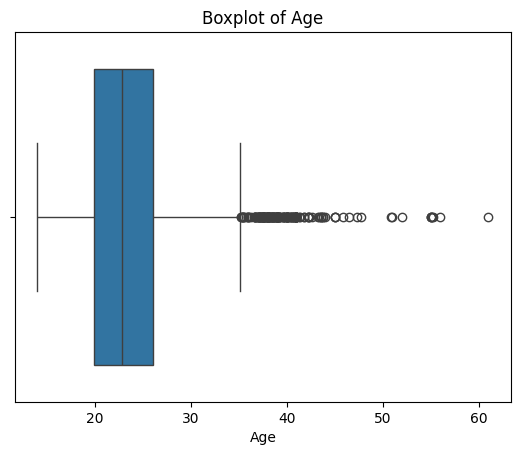

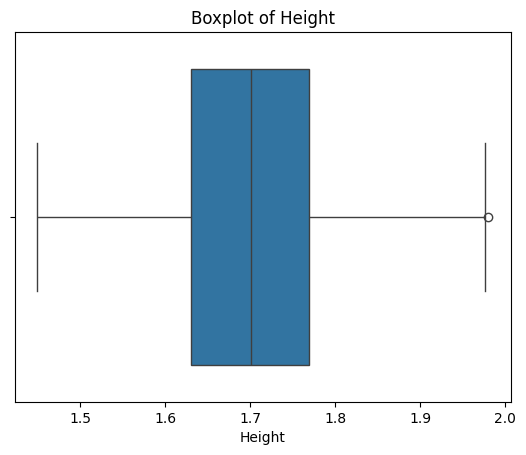

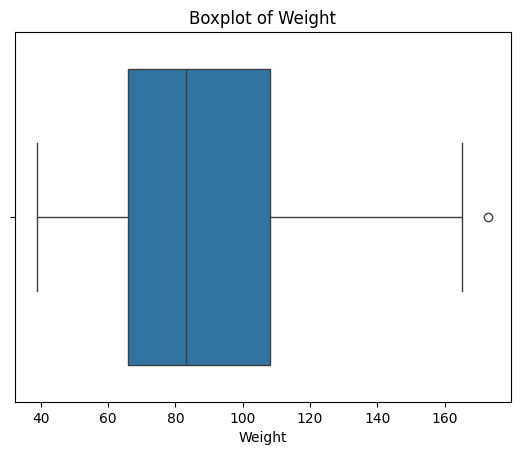

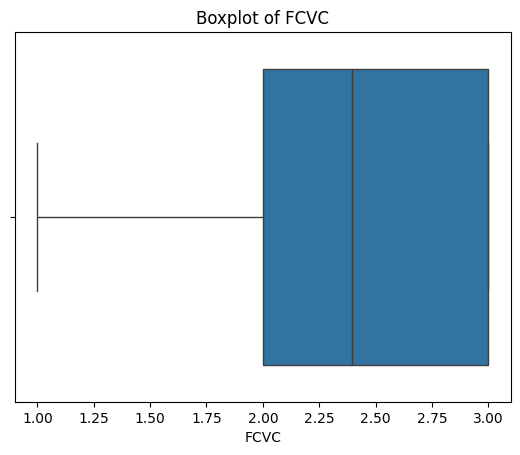

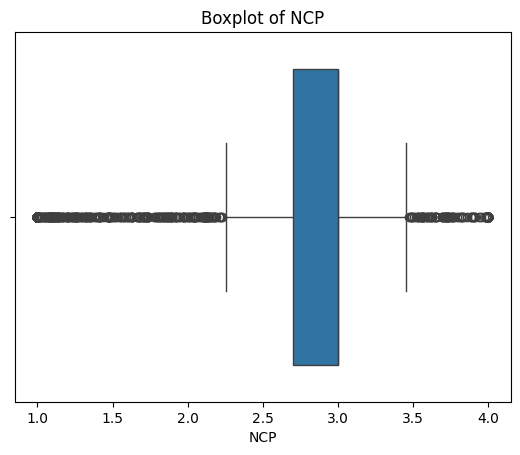

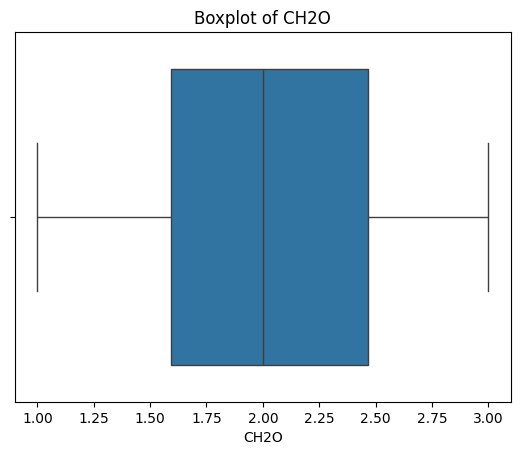

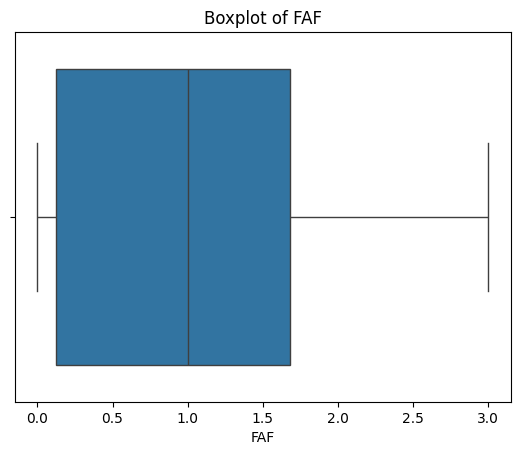

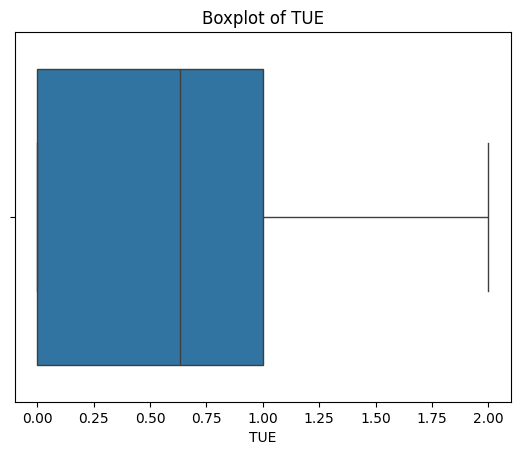

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent (%)": df.isnull().mean() * 100
})
print("Missing values:\n", missing[missing["Missing"] > 0])

print("Số dòng trùng lặp:", df.duplicated().sum())
df = df.drop_duplicates()
print("Kích thước sau khi xóa trùng lặp:", df.shape)

numeric_df = df.select_dtypes(include=np.number)
outlier_results = []

for col in numeric_df.columns:
    Q1 = numeric_df[col].quantile(0.25)
    Q3 = numeric_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((numeric_df[col] < lower) | (numeric_df[col] > upper)).sum()

    outlier_results.append({
        "Column": col,
        "Outlier Count": count,
        "Outlier Percent (%)": count / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
print("Outlier summary:\n", outlier_summary)

for col in numeric_df.columns:
    if numeric_df[col].nunique() > 1:
        sns.boxplot(x=numeric_df[col])
        plt.title(f"Boxplot of {col}")
        plt.show()
        plt.close()



In [14]:
print(df.dtypes)

cat_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

print("Các cột cần xem xét Encoding:")
print(cat_cols.tolist())

num_cols = df.select_dtypes(include="number").columns
print("Các cột dạng số:")
print(num_cols.tolist())

Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object
Các cột cần xem xét Encoding:
['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS', 'NObeyesdad']
Các cột dạng số:
['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']


In [15]:

import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

target = "NObeyesdad"

cat_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

feature_cat_cols = [
    col for col in cat_cols if col != target
]

# 1. One-Hot Encoding
df_onehot = pd.get_dummies(
    df,
    columns=feature_cat_cols,
    dtype=int
)

# 2. Ordinal Encoding
df_ordinal = df.copy()

ordinal_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

df_ordinal[feature_cat_cols] = ordinal_encoder.fit_transform(
    df_ordinal[feature_cat_cols]
)

# 3. So sánh
for name, data in {
    "One-Hot Encoding": df_onehot,
    "Ordinal Encoding": df_ordinal
}.items():
    print(f"\n===== {name} =====")
    print("Kích thước:", data.shape)
    print(data.head())



===== One-Hot Encoding =====
Kích thước: (2087, 32)
    Age  Height  Weight  FCVC  NCP  CH2O  FAF  TUE           NObeyesdad  \
0  21.0    1.62    64.0   2.0  3.0   2.0  0.0  1.0        Normal_Weight   
1  21.0    1.52    56.0   3.0  3.0   3.0  3.0  0.0        Normal_Weight   
2  23.0    1.80    77.0   2.0  3.0   2.0  2.0  1.0        Normal_Weight   
3  27.0    1.80    87.0   3.0  3.0   2.0  2.0  0.0   Overweight_Level_I   
4  22.0    1.78    89.8   2.0  1.0   2.0  0.0  0.0  Overweight_Level_II   

   Gender_Female  ...  SCC_yes  CALC_Always  CALC_Frequently  CALC_Sometimes  \
0              1  ...        0            0                0               0   
1              1  ...        1            0                0               1   
2              0  ...        0            0                1               0   
3              0  ...        0            0                1               0   
4              0  ...        0            0                0               1   

   CALC_no  MTR

In [16]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

target = "NObeyesdad"

X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Kích thước tập train:", X_train.shape)
print("Kích thước tập test:", X_test.shape)

print("\nCột số:", numeric_features)
print("Cột phân loại:", categorical_features)


Kích thước tập train: (1669, 16)
Kích thước tập test: (418, 16)

Cột số: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Cột phân loại: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


In [17]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler
)

preprocessor_onehot = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

preprocessor_ordinal = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ), categorical_features)
])

preprocessor_logistic_onehot = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

preprocessor_logistic_ordinal = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ), categorical_features)
])


In [18]:

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

models = {}

models["Decision Tree - One-Hot"] = Pipeline([
    ("preprocessor", preprocessor_onehot),
    ("model", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

models["Decision Tree - Ordinal"] = Pipeline([
    ("preprocessor", preprocessor_ordinal),
    ("model", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

models["Random Forest - One-Hot"] = Pipeline([
    ("preprocessor", preprocessor_onehot),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ))
])

models["Random Forest - Ordinal"] = Pipeline([
    ("preprocessor", preprocessor_ordinal),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ))
])

models["Logistic Regression - One-Hot"] = Pipeline([
    ("preprocessor", preprocessor_logistic_onehot),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

models["Logistic Regression - Ordinal"] = Pipeline([
    ("preprocessor", preprocessor_logistic_ordinal),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: huấn luyện hoàn tất")


Decision Tree - One-Hot: huấn luyện hoàn tất
Decision Tree - Ordinal: huấn luyện hoàn tất
Random Forest - One-Hot: huấn luyện hoàn tất
Random Forest - Ordinal: huấn luyện hoàn tất
Logistic Regression - One-Hot: huấn luyện hoàn tất
Logistic Regression - Ordinal: huấn luyện hoàn tất


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)
import pandas as pd

results = []

for name, model in models.items():

    y_train_pred = model.predict(X_train)
    y_pred = model.predict(X_test)

    y_proba = model.predict_proba(X_test)
    classes = model.named_steps["model"].classes_

    results.append({
        "Model": name,

        "Train Accuracy": accuracy_score(
            y_train, y_train_pred
        ),

        "Test Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "Precision (Macro)": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall (Macro)": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "F1-score (Macro)": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Log Loss": log_loss(
            y_test, y_proba,
            labels=classes
        )
    })

    print("\n" + "=" * 60)
    print(f"MODEL: {name}")

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test, y_pred,
        labels=classes
    ))

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score (Macro)",
    ascending=False
)

print("\nBẢNG SO SÁNH CÁC MÔ HÌNH")
print(results_df.round(4).to_string(index=False))



MODEL: Decision Tree - One-Hot

Classification Report:
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.96      0.97        53
      Normal_Weight       0.88      0.88      0.88        57
     Obesity_Type_I       0.96      0.93      0.94        70
    Obesity_Type_II       0.97      0.98      0.98        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.86      0.87      0.86        55
Overweight_Level_II       0.93      0.97      0.95        58

           accuracy                           0.94       418
          macro avg       0.94      0.94      0.94       418
       weighted avg       0.94      0.94      0.94       418

Confusion Matrix:
[[51  2  0  0  0  0  0]
 [ 1 50  0  0  0  6  0]
 [ 0  0 65  1  0  2  2]
 [ 0  0  1 59  0  0  0]
 [ 0  0  0  1 64  0  0]
 [ 0  5  0  0  0 48  2]
 [ 0  0  2  0  0  0 56]]

MODEL: Decision Tree - Ordinal

Classification Report:
                     precis